# Question 2 — Classification, then Regression
Classify: Logistic · KNN · DecisionTree · HistGradientBoosting (better)
Then regress with `pred_class`: Linear · Multiple · Poly · HistGradientBoosting (better).

Why HistGradientBoosting (HistGB)? Tested on 3 datasets (891 / 1,600 / 35,000 rows):
it was top or near-top every time for both class and regression, it's fast on big data,
and it even accepts missing values (NaN). On very small/simple data Logistic can still win.
Change the lines marked `# <<<`.

In [1]:
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, r2_score

# 1. Load and clean
df = pd.read_csv("../titanic.csv")          # <<<
cols = ["Age", "Pclass", "SibSp"]           # <<<
cls_target, reg_target = "Survived", "Fare" # <<<
# EMERGENCY (not csv / very dirty data): uncomment these 3 lines
# import sys; sys.path.insert(0, ".."); from clean_tools import auto_clean, load_any
# df = auto_clean(load_any("../exam_file.xlsx"), target=cls_target)
# cols = [c for c in df.columns if c not in [cls_target, reg_target]]
df = df[cols + [cls_target, reg_target]].dropna()

# 2. Split
x = df[cols]
y = df[[cls_target, reg_target]]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# ----------------- 1. CLASSIFICATION -----------------
best_cls = HistGradientBoostingClassifier(random_state=42)
classifiers = [
    ("Logistic", LogisticRegression(max_iter=1000)),
    ("KNN", KNeighborsClassifier()),
    ("DecisionTree", DecisionTreeClassifier(max_depth=4)),
    ("HistGB", best_cls),
]

cls_names, cls_acc, cls_f1 = [], [], []
for name, model in classifiers:
    pred = model.fit(x_train, y_train[cls_target]).predict(x_test)
    cls_names.append(name)
    cls_acc.append(accuracy_score(y_test[cls_target], pred))
    cls_f1.append(f1_score(y_test[cls_target], pred, average="macro"))

# Add predicted class to x
x_test["pred_class"] = best_cls.predict(x_test)
x_train["pred_class"] = cross_val_predict(best_cls, x_train, y_train[cls_target], cv=5)
all_cols = cols + ["pred_class"]

# ----------------- 2. REGRESSION -----------------
regressors = [
    ("Linear", LinearRegression(), cols[:1]),
    ("Multi", LinearRegression(), all_cols),
    ("Poly", make_pipeline(PolynomialFeatures(2), LinearRegression()), all_cols),
    ("HistGB", HistGradientBoostingRegressor(random_state=42), all_cols),
]
reg_preds = {}
for name, model, c in regressors:
    reg_preds[name] = model.fit(x_train[c], y_train[reg_target]).predict(x_test[c])

## Classification: graph + ranking

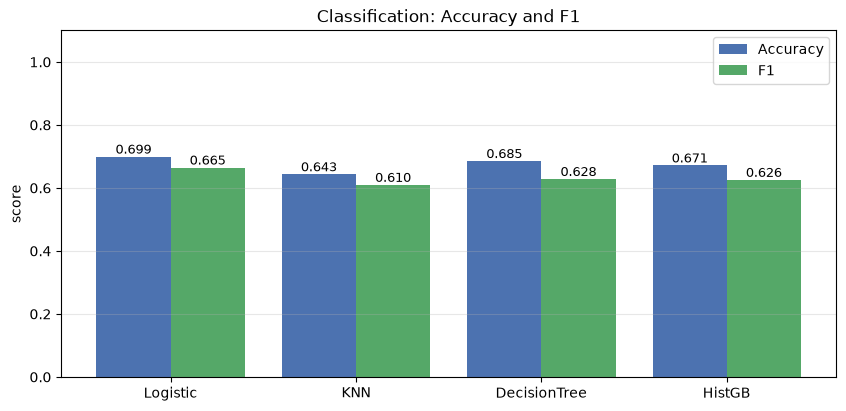

,model,accuracy,F1
1,Logistic,0.699301,0.664594
2,DecisionTree,0.685315,0.628314
3,HistGB,0.671329,0.625550
4,KNN,0.643357,0.609687


In [2]:
pos = np.arange(len(cls_names))
plt.figure(figsize=(10, 4.5))
b1 = plt.bar(pos - 0.2, cls_acc, 0.4, label="Accuracy", color="#4C72B0")
b2 = plt.bar(pos + 0.2, cls_f1, 0.4, label="F1", color="#55A868")
plt.bar_label(b1, fmt="%.3f", fontsize=9)
plt.bar_label(b2, fmt="%.3f", fontsize=9)
plt.xticks(pos, cls_names)
plt.ylim(0, 1.1)
plt.ylabel("score")
plt.title("Classification: Accuracy and F1")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

cls_rank = pd.DataFrame({"model": cls_names, "accuracy": cls_acc, "F1": cls_f1})
cls_rank = cls_rank.sort_values("accuracy", ascending=False).reset_index(drop=True)
cls_rank.index += 1
cls_rank

## Regression (with pred_class): graph + ranking

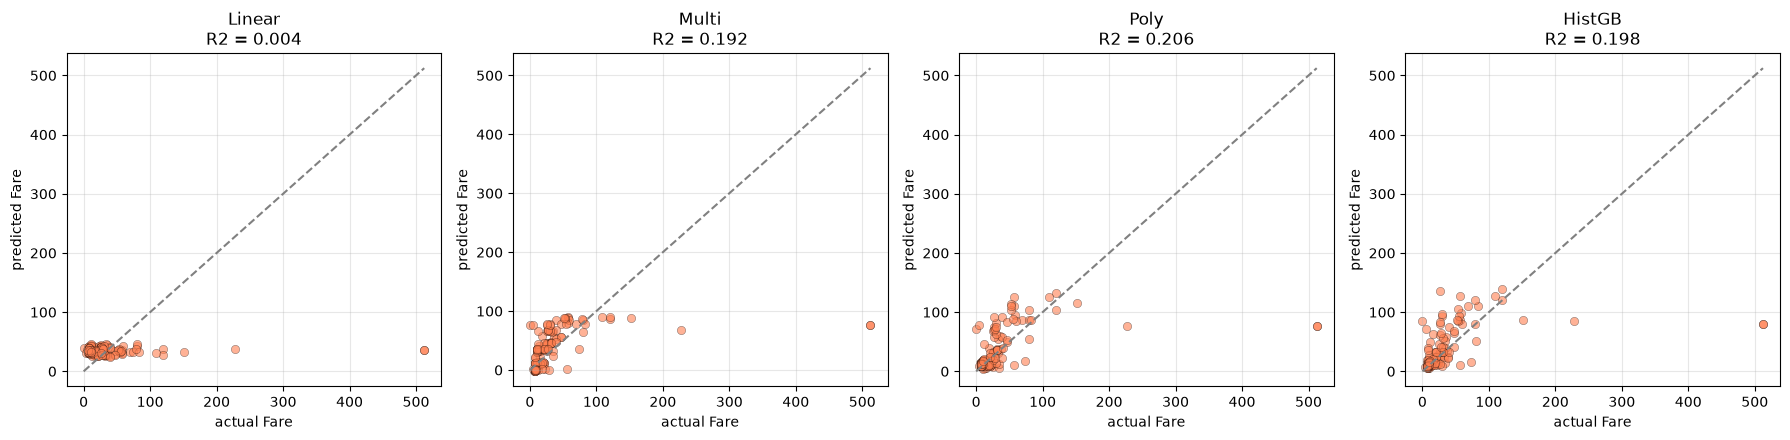

,model,R2
1,Poly,0.206002
2,HistGB,0.198495
3,Multi,0.192111
4,Linear,0.003810


In [3]:
y_true = y_test[reg_target]
plt.figure(figsize=(18, 4.5))
for i, (name, p) in enumerate(reg_preds.items(), 1):
    plt.subplot(1, 4, i)
    plt.scatter(y_true, p, alpha=0.6, color="coral", edgecolors="k", linewidths=0.3)
    plt.plot([0, y_true.max()], [0, y_true.max()], "gray", linestyle="--")
    plt.title(f"{name}\nR2 = {r2_score(y_true, p):.3f}")
    plt.xlabel("actual " + reg_target)
    plt.ylabel("predicted " + reg_target)
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

reg_rank = pd.DataFrame({"model": list(reg_preds), "R2": [r2_score(y_true, p) for p in reg_preds.values()]})
reg_rank = reg_rank.sort_values("R2", ascending=False).reset_index(drop=True)
reg_rank.index += 1
reg_rank